# 04 - Findings and recommendations

This notebook turns the modelling results into plain-language findings. No new modelling happens here; every number is read from the files saved by notebook 03.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = Path("../reports/figures")
res = json.loads(Path("../reports/model_results.json").read_text())
preds = pd.read_csv("../reports/test_predictions.csv")

cv = pd.DataFrame(res["cv_table"]).set_index("model")
test = pd.DataFrame(res["test"]).T
to_pct = lambda log_mae: (np.exp(log_mae) - 1) * 100

## Finding 1: price level is mostly decided by the product, not the route

In [2]:
lanes = pd.read_csv("../data/processed/rate_lanes_clean.csv")
tbl = lanes.groupby("product_code")["base_rate_inr"].agg(lanes="size", median_rate_inr="median").round(1)
tbl

,lanes,median_rate_inr
product_code,,
A,84,65.6
D,814,30.4
I,382,1816.8
V,16,6853.7


Product `I` lanes cost roughly 56 times what the other products cost at the entry slab. Region matters too: even with product `I` set aside, NORTH, EAST and SOUTH2 sit above WEST1 and SOUTH1. But the product mix differs by region (only NORTH carries product `V`), so compare regions within a product.

## Finding 2: rate-card attributes predict price well, but not equally well for every customer

In [3]:
summary = pd.DataFrame({
    "Typical error, cross-validated (log MAE)": cv["cv_mae_log"],
    "Roughly this far off": cv["cv_mae_log"].map(lambda v: f"{to_pct(v):.0f}%"),
}).sort_values("Typical error, cross-validated (log MAE)")
summary.round(3)

,"Typical error, cross-validated (log MAE)",Roughly this far off
model,,
Ridge,0.191,21%
Gradient boosting,0.262,30%
Random forest,0.274,32%
Baseline (median),1.449,326%


In [4]:
best = res["selected_model"]
print(f"Selected model: {best}")
print(f"Held-out customers: typical error {to_pct(test.loc[best, 'mae_log']):.0f}% "
      f"(median absolute error {test.loc[best, 'median_abs_pct_error']:.0f}%)")
print(f"Median-price guess on the same lanes: median absolute error {test.loc['Baseline (median)', 'median_abs_pct_error']:.0f}%")
print(f"Spread between customers in cross-validation: +/- {cv.loc[best, 'mae_std']:.2f} log points")

Selected model: Ridge
Held-out customers: typical error 11% (median absolute error 9%)
Median-price guess on the same lanes: median absolute error 39%
Spread between customers in cross-validation: +/- 0.16 log points


Put simply: on the two customers it had never seen, the model's typical miss was a small fraction of the real entry price. A flat "always guess the median" rule misses by well over a third at the median, and is wildly off on the expensive product, which is where the log-scale error shows the real gap. Cross-validation adds a caution: the error bounces from one held-out customer to the next (the spread is shown above), and two test customers is a small sample. One more point matters for how far to trust any of this. The data is simulated with price patterns I chose, so these scores show that the method works, not how accurate it would be on real contracts.

## Finding 3: where the model is least reliable

In [5]:
preds["abs_pct_error"] = preds["pct_error"].abs()
seg = (preds.groupby(["product_code", "freight_type"])
       .agg(lanes=("abs_pct_error", "size"), median_abs_pct_error=("abs_pct_error", "median"))
       .query("lanes >= 5").round(1).sort_values("median_abs_pct_error", ascending=False))
seg

lanes  median_abs_pct_error
product_code freight_type                             
D            R2R              10                  12.8
             L2L              25                  10.2
I            Z2ZI             78                   9.3
D            Z2Z             127                   8.6

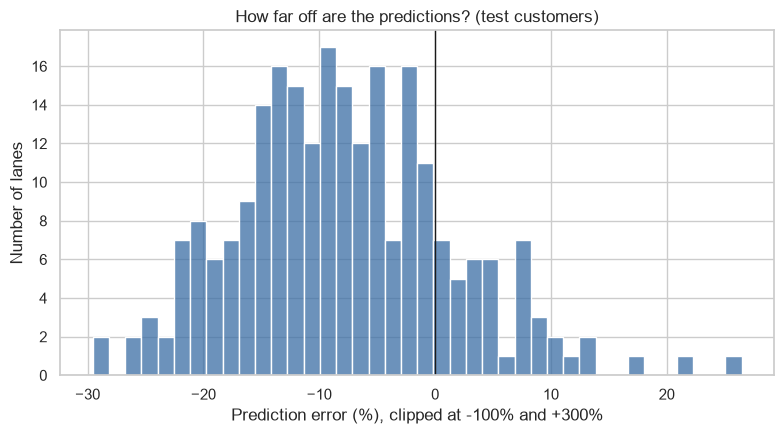

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(preds["pct_error"].clip(-100, 300), bins=40, ax=ax, color="#3b6ea5")
ax.axvline(0, color="k", linewidth=1)
ax.set(title="How far off are the predictions? (test customers)",
       xlabel="Prediction error (%), clipped at -100% and +300%", ylabel="Number of lanes")
plt.tight_layout()
fig.savefig(FIG_DIR / "08_error_distribution.png", dpi=150)
plt.show()

About nine in ten lanes sit within a fifth of the true price. A small tail is off by more, and those are the interesting ones, covered next.

## Finding 4: the model can build a review list

In [7]:
THRESHOLD = 25
review = preds[preds["abs_pct_error"] > THRESHOLD].copy()
print(f"{len(review)} of {len(preds)} test lanes ({len(review) / len(preds):.0%}) differ from the model by more than {THRESHOLD}%")
review[["lead_region", "product_code", "freight_type", "origin_zone", "dest_zone",
        "actual_inr", "predicted_inr", "pct_error"]].sort_values("pct_error", key=abs, ascending=False).head(10)

5 of 240 test lanes (2%) differ from the model by more than 25%


,lead_region,product_code,freight_type,origin_zone,dest_zone,actual_inr,predicted_inr,pct_error
142,EAST,D,Z2Z,C,K,44.22,31.15,-29.55
130,EAST,D,Z2Z,L,F,46.12,32.85,-28.78
56,WEST1,D,Z2Z,I,I,34.55,25.38,-26.53
92,WEST1,I,Z2ZI,IND,7,1252.69,1584.10,26.46
143,EAST,D,Z2Z,L,D,58.73,43.73,-25.54


A large gap does not mean the contract is wrong. It means the price differs from what similar rate cards charge, and someone should know why. A deliberate discount, a special deal, or a typing slip would all show up here.

## Recommendations

1. **Use the model as a second pair of eyes at renewal time.** Run each lane through it and look at the lanes that differ from the prediction by more than 25% (a starting threshold; adjust it once the team sees how many flags it can handle). Treat the output as a prompt for a question, never as the price.
2. **Do not use it for products it has barely seen.** Products `A` and `V` have few lanes (84 and 16). Predictions there would be guesses (product `V` has only 16 lanes, all from one customer).
3. **Gather more customers before trusting it further.** Everything here rests on eight simulated customers, and one of them supplies close to half the lanes. More customers is the single biggest improvement available.
4. **Add the missing context.** Zone-to-zone distance, shipment volume, cost to serve and competitor rates would likely explain much of what the model currently misses. The competitor rate cards already collected for the Rate Simulator are a natural start.
5. **Validate on real data inside the business.** Run the same notebooks on real rate cards behind the company firewall, where the confidentiality of customer prices is protected.

## Limitations

- Only the entry slab is predicted. Heavier weight slabs, surcharges and value-added services are out of scope.
- **The data is synthetic.** It copies the layout of a real courier rate-card export, but prices come from a recipe I wrote (product, region, zone and customer effects plus noise). Real contracts are messier, so expect lower accuracy outside this project.
- Pricing is shaped by negotiation and strategy, which a table of rate-card attributes can only partly explain.
- The test set holds two customers. Treat the test score as one data point and the cross-validated score as the more cautious estimate.

## Next steps

- Extend the target to a full-shipment cost (entry slab plus per-extra-weight charges) for a standard weight.
- Test whether adding competitor rate cards improves accuracy.
- Surface the "differs from similar contracts" flag inside the Rate Simulator itself.